# TECH2 term paper (H26): Boom, slump, recovery? Green energy innovation in European patent data

Candidate numbers: ...

## Task 1 — Import and prepare the data

All data are read here, and Tasks 2–5 only use the three objects created below:

| Object | One row per | Columns |
|---|---|---|
| `patents` | sample patent (priority year 2000–2019) | `appln_id`, `prio_year` |
| `green` | (green patent, Y02E code) | `appln_id`, `prio_year`, `code`, `main_group`, `technology` |
| `applicants` | (sample patent, applicant), region duplicates removed | `appln_id`, `app_name`, `ctry_code`, `app_share` |

Each file is read inside a function that keeps only the columns and rows we need, so the full file only exists in memory while the function runs.

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

In [10]:
# Relative paths with the original file names, as required by the exam
FILE_PATENTS = 'data/202608_EPO_IPC.txt'
FILE_CPC = 'data/202608_CPC_Classes.txt'
FILE_APPLICANTS = 'data/202608_EPO_App_reg.txt'

# Table 1: main group number (two digits before the slash) -> label
MAIN_GROUPS = {
    10: 'Renewable energy',
    20: 'Efficient combustion',
    30: 'Nuclear energy',
    40: 'Efficient power transmission',
    50: 'Non-fossil fuels',
    60: 'Storage and hydrogen',
    70: 'Other energy conversion',
}

# Table 2: first digit after the slash in main group 10 -> technology.
# Digits not listed here (e.g. 10/0...) belong to no technology.
TECHNOLOGIES = {
    '4': 'Solar',
    '5': 'Solar',
    '6': 'Solar',
    '7': 'Wind',
    '1': 'Other renewables',
    '2': 'Other renewables',
    '3': 'Other renewables',
}

In [11]:
def read_patents(path, start=2000, end=2019):
    """
    Read the sample of EPO patent applications with their priority year.

    Parameters
    ----------
    path : str
        Path to 202608_EPO_IPC.txt.
    start : int, optional
        First priority year in the sample.
    end : int, optional
        Last priority year in the sample.

    Returns
    -------
    pandas.DataFrame
        One row per sample patent, with columns appln_id and prio_year.
    """
    # Only two of the four columns are needed; IPC codes are the largest part of the file
    df = pd.read_csv(path, sep='|', usecols=['appln_id', 'prio_year'])

    # Keep the sample years only
    df = df.loc[(df['prio_year'] >= start) & (df['prio_year'] <= end)]

    # The file has one row per IPC code, so a patent appears many times.
    # drop_duplicates() removes repeated rows, leaving one row per patent.
    return df.drop_duplicates().reset_index(drop=True)

In [12]:
def read_green(path, patents, chunksize=1_000_000):
    """
    Read the Y02E codes of sample patents and label them with Tables 1 and 2.

    Parameters
    ----------
    path : str
        Path to 202608_CPC_Classes.txt.
    patents : pandas.DataFrame
        Sample patents from read_patents(), with appln_id and prio_year.
    chunksize : int, optional
        Number of rows read at a time.

    Returns
    -------
    pandas.DataFrame
        One row per (green patent, Y02E code), with columns appln_id,
        prio_year, code, main_group and technology.
    """
    # The file has 35.6 million rows, but only a few percent are Y02E codes.
    # Reading it in chunks (chunksize= returns the file piece by piece) and
    # keeping only Y02E rows of sample patents keeps peak memory low.
    pieces = []
    for chunk in pd.read_csv(
        path, sep='|', usecols=['appln_id', 'CPC_Class'], chunksize=chunksize
    ):
        # .str.startswith() tests the start of each string, so this keeps all Y02E codes
        keep = chunk['CPC_Class'].str.startswith('Y02E') & chunk['appln_id'].isin(
            patents['appln_id']
        )
        pieces.append(chunk.loc[keep])
    green = pd.concat(pieces, ignore_index=True)
    del pieces

    # The file pads codes with a varying number of spaces ('Y02E  10/72'),
    # so remove all spaces (.str.replace) to get one spelling per code: 'Y02E10/72'
    green['code'] = green['CPC_Class'].str.replace(' ', '')
    green = green.drop(columns='CPC_Class').drop_duplicates()

    # .str[4:6] slices characters 4-5 of each code: the main group (Table 1)
    group = green['code'].str[4:6].astype(int)
    green['main_group'] = group.map(MAIN_GROUPS)

    # Character 7 is the first digit after the slash: the technology (Table 2),
    # which only exists inside main group 10
    green['technology'] = green['code'].str[7].map(TECHNOLOGIES).where(group == 10)

    # Add the priority year so later tasks don't need another merge
    green = pd.merge(green, patents, on='appln_id', how='left')
    return green[['appln_id', 'prio_year', 'code', 'main_group', 'technology']]

In [13]:
def read_applicants(path, patents):
    """
    Read the applicants of sample patents.

    Parameters
    ----------
    path : str
        Path to 202608_EPO_App_reg.txt.
    patents : pandas.DataFrame
        Sample patents from read_patents().

    Returns
    -------
    pandas.DataFrame
        One row per (sample patent, applicant), with columns appln_id,
        app_name, ctry_code and app_share.
    """
    # The file starts with a byte order mark; encoding='utf-8-sig' removes it
    # so the first column name is read correctly.
    # By default pandas reads the text 'NA' as missing, but 'NA' is the country
    # code of Namibia: keep_default_na=False with na_values=[''] makes only
    # empty fields count as missing.
    df = pd.read_csv(
        path,
        sep='|',
        usecols=['appln_id', 'app_name', 'ctry_code', 'app_share'],
        encoding='utf-8-sig',
        keep_default_na=False,
        na_values=[''],
    )

    # Keep applicants of sample patents only (all of them, not just green ones,
    # because the Task 1 numbers are over the whole sample)
    df = df.loc[df['appln_id'].isin(patents['appln_id'])]

    # An applicant linked to several regions appears on identical rows once the
    # region columns are dropped; remove them so app_share is not counted twice
    df = df.drop_duplicates()

    # .str.upper() gives one spelling per name, done after the duplicates
    # are removed so it cannot merge two different rows
    df['app_name'] = df['app_name'].str.upper()
    return df.reset_index(drop=True)

In [14]:
# Read all data needed for Tasks 2-5; the sample patents are read first
# because the other two readers use them to filter rows
patents = read_patents(FILE_PATENTS)
green = read_green(FILE_CPC, patents)
applicants = read_applicants(FILE_APPLICANTS, patents)

# Short size report: rows and memory of each object
for name, df in {'patents': patents, 'green': green, 'applicants': applicants}.items():
    print(
        f'{name:<11}{len(df):>11,} rows {df.memory_usage(deep=True).sum() / 1e6:>6.0f} MB'
    )

patents      2,835,599 rows     45 MB
green          141,882 rows     26 MB
applicants   3,059,537 rows    433 MB


### Checkpoints

Our numbers next to the checkpoints given in the exam text.

In [15]:
# Each checkpoint counts something different:
# - sample patents: patents has one row per patent, so its length
# - green patents: green has one row per (patent, code), so count unique patents.
#   .nunique() counts distinct values, so a patent with many codes counts once.
# - app_share: sum over all applicants of sample patents
checkpoints = pd.DataFrame(
    {
        'exam': [2_835_599, 114_924, 2_835_140],
        'ours': [
            len(patents),
            green['appln_id'].nunique(),
            round(applicants['app_share'].sum()),
        ],
    },
    index=['Patents in the sample', 'Green energy patents', 'Sum of app_share'],
)
checkpoints['match'] = checkpoints['exam'] == checkpoints['ours']
checkpoints

,exam,ours,match
Patents in the sample,2835599,2835599,True
Green energy patents,114924,114924,True
Sum of app_share,2835140,2835140,True


### Overview of the data

In [16]:
# Y02E codes per green patent: green has one row per (patent, code),
# so the group size per patent is its number of codes
codes_per_patent = green.groupby('appln_id').size().mean()

# Main groups per green patent: count distinct main groups per patent,
# then count the patents with more than one
groups_per_patent = green.groupby('appln_id')['main_group'].nunique()
multi_group = (groups_per_patent > 1).sum()

# Countries per sample patent, counted the same way over all applicants
countries_per_patent = applicants.groupby('appln_id')['ctry_code'].nunique()
multi_country = (countries_per_patent > 1).sum()

overview = pd.DataFrame(
    {
        'value': [
            f'{codes_per_patent:.2f}',
            f'{multi_group:,}',
            f'{multi_country:,}',
        ]
    },
    index=[
        'Average Y02E codes per green energy patent',
        'Green energy patents in more than one main group',
        'Sample patents with applicants in more than one country',
    ],
)
overview

,value
Average Y02E codes per green energy patent,1.23
Green energy patents in more than one main group,"4,359"
Sample patents with applicants in more than one country,"58,955"


### One row per patent and category

Tasks 3–5 count a patent once in each category it belongs to, where a category is a main group (Table 1) or a technology (Table 2). The table below does this once for all later tasks.

In [17]:
# Stack the Table 1 labels (main_group) and the Table 2 labels (technology)
# into one 'category' column, so any label can be looked up the same way.
# Codes without a technology (NaN) are dropped from the technology part only,
# so Y02E 10/0... codes still count in main group 10 (Renewable energy).
categories = pd.concat(
    [
        green[['appln_id', 'prio_year', 'main_group']].rename(
            columns={'main_group': 'category'}
        ),
        green[['appln_id', 'prio_year', 'technology']]
        .rename(columns={'technology': 'category'})
        .dropna(),
    ],
    ignore_index=True,
)

# A patent with several codes in the same category must count once there
categories = categories.drop_duplicates(ignore_index=True)
print(f'categories: {len(categories):,} rows (patent, category)')

categories: 162,166 rows (patent, category)


## Task 2 — Has green energy patenting slumped?

## Task 3 — How has the technology mix changed?

## Task 4 — Wind versus solar

## Task 5 — Who drives green energy innovation?

We use fractional counting: each patent is split between its applicants by `app_share`, so a country's or applicant's number of patents is the sum of `app_share` over its rows.

In [18]:
# Only applicants of green energy patents are needed in this task. Filtering
# once here keeps the merge inside top_n() small (about 126,000 rows
# instead of 3 million)
green_applicants = applicants.loc[applicants['appln_id'].isin(categories['appln_id'])]

In [19]:
def top_n(category, by, start=2000, end=2019, n=10):
    """
    Return the top n countries or applicants by fractional patent count.

    Parameters
    ----------
    category : str
        Category label from Table 1 or Table 2, e.g. 'Storage and hydrogen'
        or 'Wind'.
    by : str
        Column to rank: 'ctry_code' for countries or 'app_name' for applicants.
    start, end : int, optional
        First and last priority year of the period.
    n : int or None, optional
        Number of countries or applicants to return. None returns all.

    Returns
    -------
    pandas.Series
        Fractional patent counts indexed by country or applicant, largest
        first.

    Examples
    --------
    >>> top_n('Wind', 'ctry_code', 2010, 2014, n=5)
    """
    # Patents in the category and period. categories has one row per
    # (patent, category), so each patent's shares are added only once.
    mask = (
        (categories['category'] == category)
        & (categories['prio_year'] >= start)
        & (categories['prio_year'] <= end)
    )
    selected = categories.loc[mask, ['appln_id']]

    # Inner join: keep the applicants of the selected patents only
    # (patents without an applicant have no shares to add)
    rows = pd.merge(selected, green_applicants, on='appln_id', how='inner')

    # Fractional counting: sum app_share per country or applicant
    return rows.groupby(by)['app_share'].sum().sort_values(ascending=False).head(n)

In [20]:
# Check of the fractional counting: summed over ALL countries, the shares
# should equal the number of patents in the category and period (minus the
# few patents without applicants or with shares that don't add up to 1)
for start, end in [(2005, 2009), (2015, 2019)]:
    in_period = (
        (categories['category'] == 'Renewable energy')
        & (categories['prio_year'] >= start)
        & (categories['prio_year'] <= end)
    )
    total = top_n('Renewable energy', 'ctry_code', start, end, n=None).sum()
    print(f'{start}–{end}: {in_period.sum():,} patents, shares sum to {total:,.1f}')

2005–2009: 10,676 patents, shares sum to 10,676.0
2015–2019: 11,797 patents, shares sum to 11,796.0


In [21]:
def plot_top(results, titles, suptitle, sharex=False, max_len=35):
    """
    Plot top-n results from top_n() as horizontal bar panels side by side.

    Parameters
    ----------
    results : list of pandas.Series
        One result from top_n() per panel.
    titles : list of str
        Title of each panel.
    suptitle : str
        Title of the whole figure.
    sharex : bool, optional
        Use the same x-axis scale in all panels.
    max_len : int, optional
        Labels longer than this are cut, so long applicant names don't squash
        the bars. The results themselves keep the full names.
    """
    fig, axes = plt.subplots(1, len(results), figsize=(12, 4.5), sharex=sharex)

    # strict=True: raise an error if the lists have different lengths
    for ax, result, title in zip(axes, results, titles, strict=True):
        # barh draws the first bar at the bottom, so reverse the order
        # (.iloc[::-1] steps through the rows backwards) to put the largest on top
        result = result.iloc[::-1]

        # .str[:max_len] keeps the first max_len characters of each label
        ax.barh(result.index.str[:max_len], result.values, color='steelblue')
        ax.set_title(title)
        ax.set_xlabel('Patents (fractional count)')
        ax.grid(axis='x', alpha=0.2)
        ax.set_axisbelow(True)

    fig.suptitle(suptitle)
    fig.tight_layout()

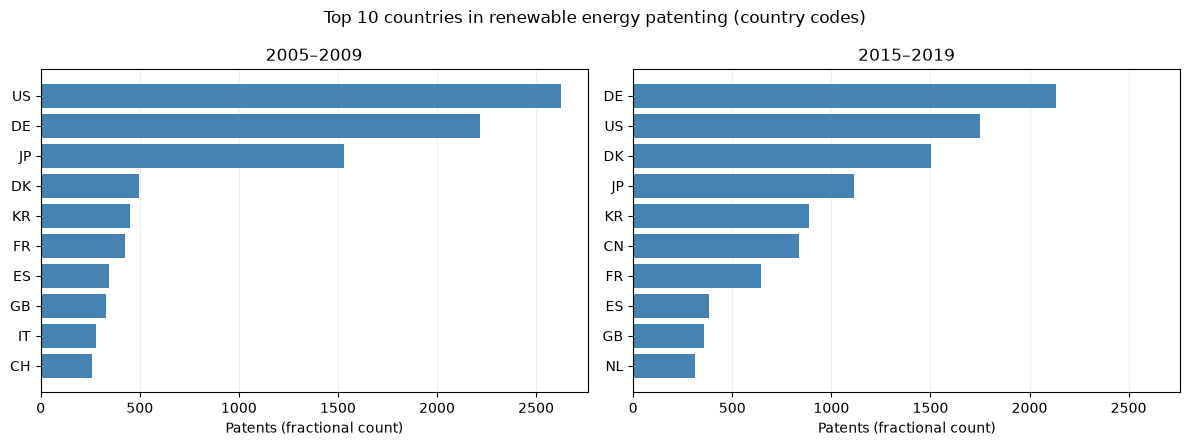

In [22]:
# Figure 1: the same x-scale (sharex=True) makes the two periods comparable
periods = [(2005, 2009), (2015, 2019)]
country_results = [
    top_n('Renewable energy', 'ctry_code', start, end) for start, end in periods
]
plot_top(
    country_results,
    [f'{start}–{end}' for start, end in periods],
    'Top 10 countries in renewable energy patenting (country codes)',
    sharex=True,
)

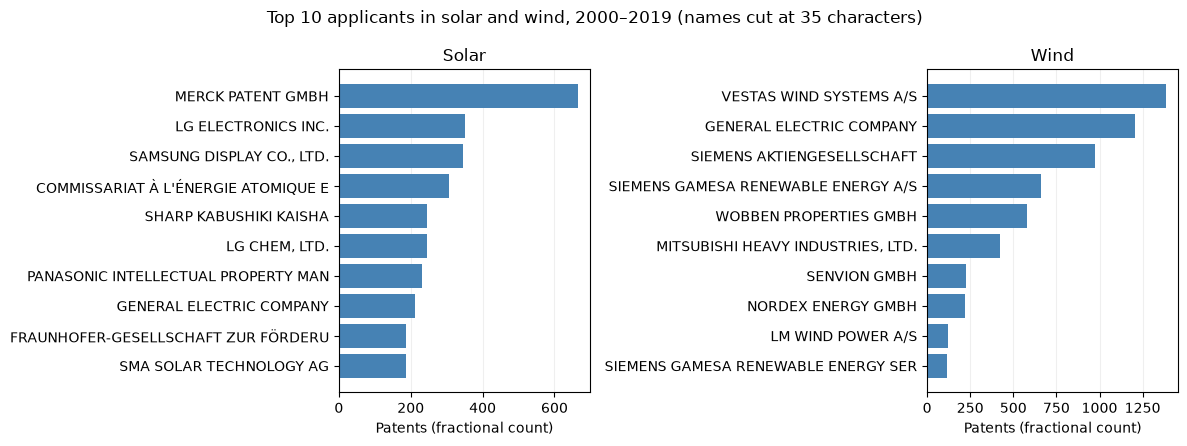

In [23]:
# Figure 2: whole sample period; separate x-scales because solar has about
# twice as many patents as wind, which would squash the wind panel
technologies = ['Solar', 'Wind']
applicant_results = [top_n(technology, 'app_name') for technology in technologies]
plot_top(
    applicant_results,
    technologies,
    'Top 10 applicants in solar and wind, 2000–2019 (names cut at 35 characters)',
)

### Answers

*In the period from 2005-2009 we saw that applicants from the US had the largest share of applications, followed by Germany and Japan. We see a bigg fall in patents down to Denmark in 4th place. Movingover to the 2015-2019 period we see that Germany have overtaken the US and that Denmark has moved ahead of Japan. The large difference between 3rd and 4th place in no longer present. 

When looking at which companies apply for the most patents there is a large presence of techology conglomerates. The companies are from countries like Germany (Merck, Fraunhofer, SMA), South Korea (LG, Samsung), Japan (Panasonic, Sharp), the US (General Electric) and Denmark (Vestas, Siemens). This is likely one reason for these countries being the top 5 in both time-periods. We also see that wind has a higher concentration of companies at the top than solar, Where the top three countries  There are two danish companies within the top 3 in wind.    *

## Task 6 — Use of online resources